# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_:
- _Student No._: 20XX-XXXXX
- _Section_: fill in

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![yes](interpmethods.png)
**Figure 1. Synthetic data interpolation.**

![no](realcubic.png)
**Figure 2. Real-world data reconstruction.**

### Report discussion

**Interpolator comparison:**
Figure 1 shows how different scipy interpolation methods reconstruct the sine function using a limited number of sampled points. Cubic interpolation produces the best reconstruction, followed closely by quadratic interpolation. Nearest interpolation by far produces the least accurate reconstruction, while linear interpolation produces lesser accurate plots between sample points that are further apart. This does not necessarily mean that cubic interpolation is the best interpolation method for any situation. At most, this visualizes the relative accuracy of the four methods for a smooth continuous curve such as the sine function. This does not tell us how the graphs would behave for a sharp function with many kinks and spikes.


**Sampling-level comparison:** 
Figure 2 shows how the sample size affects the interpolation of real-world data. It shows that the plot reconstruction becomes more accurate as the sample size increases. Though, this can still largely depend on what points get sampled. For example, at around x = 450, the 300-sample curve suffers a sharp spike, whereas the 100-sample curve suffers no such spike across the whole graph. This of course is a problem in the algorithm and can, in theory, be bypassed by making the iterations where the sample sizes are smaller become a subset of the iterations where the sample sizes are larger. Figure 2 at the very least shows that larger sample size decreases the total error across the entire plot.

---
## Section 2: Code

In [32]:
import numpy as np
from scipy.interpolate import interp1d
from pathlib import Path
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

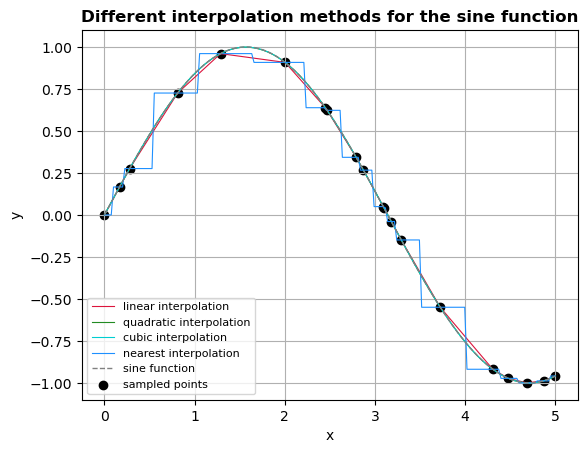

In [55]:
rnd_samples = 20

xs = np.linspace(0, 5, 200)
ys = np.sin(xs)

xs_rnd = np.sort(rng.uniform(0, 5, size=rnd_samples))
xs_rnd[0], xs_rnd[-1] = 0, 5
ys_rnd = np.sin(xs_rnd)

methods = ['linear', 'quadratic', 'cubic', 'nearest']
colors = ['crimson', 'forestgreen', 'darkturquoise', 'dodgerblue']

for method, color in zip(methods, colors):
    interpolator = interp1d(xs_rnd, ys_rnd, kind=method)
    ys_interp = interpolator(xs)
    plt.plot(xs, ys_interp, color=color, label=f"{method} interpolation", linewidth=0.8)

plt.plot(xs, ys, color='gray', linestyle='--', label='sine function', linewidth=1.0)
plt.scatter(xs_rnd, ys_rnd, color='black', alpha=1.0, label='sampled points')
plt.title('Different interpolation methods for the sine function', fontweight='bold')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(fontsize=8, loc='lower left')
plt.grid()
plt.show()

### Problem code summary

The code above graphs the sine function using several scipy interpolation methods for 20 sampled points. The primary algorithm is a for loop that iterates over the different interpolation methods(taking advantage of the interp1d functions inputs) for a concise code. It also plots the theoretical sine function and the sampled points for reference.

---

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [37]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [38]:
data = np.loadtxt('dow.txt')
print(len(data))

1024


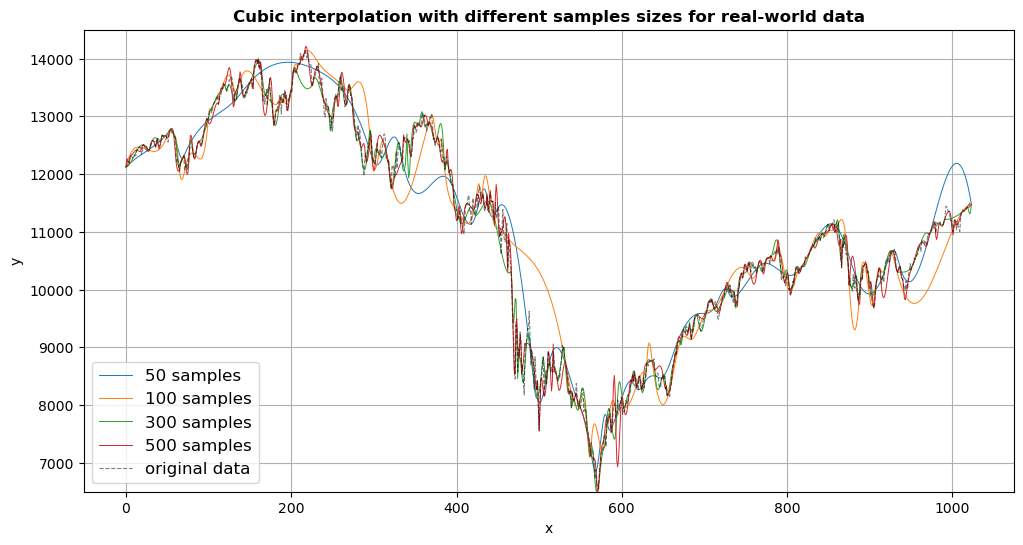

In [53]:
rnd_samples2 = [50, 100, 300, 500]
data_points = np.arange(0, len(data))

plt.figure(figsize=(12,6))
for rnd in rnd_samples2:
    xs_rnd2 = np.sort(rng.uniform(0, len(data)-1, size=rnd))
    xs_rnd2[0], xs_rnd2[-1] = 0, len(data)-1

    rounded_indices = np.round(xs_rnd2).astype(int)
    ys_rnd2 = data[rounded_indices]

    interpolator2 = interp1d(xs_rnd2, ys_rnd2, kind='cubic')
    ys_interp2 = interpolator2(data_points)

    plt.plot(data_points, ys_interp2, label=f'{rnd} samples', linewidth=0.7)

plt.plot(data_points, data, color='black', alpha=0.5, linestyle='--', label='original data', linewidth=0.8)
plt.title('Cubic interpolation with different samples sizes for real-world data', fontweight='bold')
plt.ylim(6500, 14500)
plt.xlabel('x')
plt.ylabel('y')
plt.legend(fontsize=12, loc='lower left')
plt.grid()
plt.show()

### Problem code summary

The code above interpolates different sample sizes from real world data. It similarly uses a for loop to iterate over the specified sample sizes. Some parameters were specified, such as the y-limit, figure size and line widths in order to make the discrepancies in the plots more noticeable.

---

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

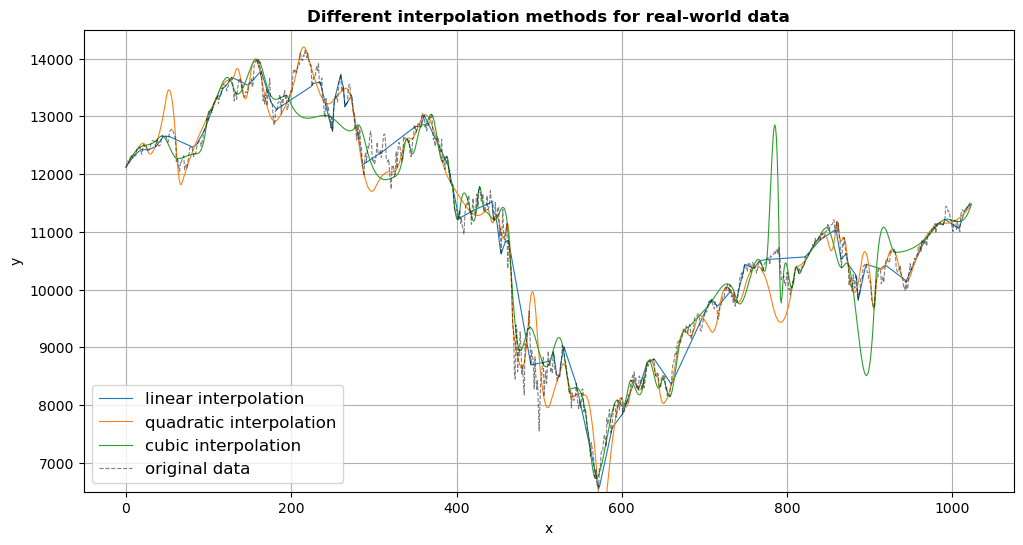

In [54]:
rnd_samples2 = 100
data_points = np.arange(0, len(data))

plt.figure(figsize=(12,6))
methods2 = ['linear', 'quadratic', 'cubic']
for method in methods2:
    xs_rnd2 = np.sort(rng.uniform(0, len(data)-1, size=rnd_samples2))
    xs_rnd2[0], xs_rnd2[-1] = 0, len(data)-1

    rounded_indices = np.round(xs_rnd2).astype(int)
    ys_rnd2 = data[rounded_indices]

    interpolator2 = interp1d(xs_rnd2, ys_rnd2, kind=method)
    ys_interp2 = interpolator2(data_points)

    plt.plot(data_points, ys_interp2, label=f'{method} interpolation', linewidth=0.8)

plt.plot(data_points, data, color='black', alpha=0.5, linestyle='--', label='original data', linewidth=0.8)
plt.title('Different interpolation methods for real-world data', fontweight='bold')
plt.ylim(6500, 14500)
plt.xlabel('x')
plt.ylabel('y')
plt.legend(fontsize=12, loc='lower left')
plt.grid()
plt.show()

### Problem code summary

The code above interpolates a sample of real world data using different interpolation methods. It similarly uses a for loop to iterate over the different methods. Some parameters were specified, such as the y-limit, figure size and line widths in order to make the discrepancies in the plots more noticeable.

---